# Tutorial 03: A cycle at its periodic state
This notebook will guide you through a full cyclic run of pyDAC.
You will learn how to:
- run the default steam-assisted TVSA cycle until it reaches its *cyclic steady state* (CSS);
- see how the run decides that it has reached it;
- read the performance of the periodic cycle: productivity, energy, recovery, purity;
- follow where the CO2 and the energy go;
- check the oxygen in the hot bed, and manage the run folder.

### Overview
- **Case:** [`../cases/03_css_tvsa.json`](../cases/03_css_tvsa.json):
  the built-in defaults on a 2D grid of 50 axial by 25 radial cells.
- **Runtime:** one CSS run in 2D of about ten minutes; it writes about 0.8 GB.
- **Same tutorial without a notebook:** the terminal commands at the end.

### Before you start
1. Install pyDAC and select its kernel, as in [tutorial 01](01_first_steps.ipynb).
2. Check that you have about 1 GB of free disk space.
3. Run the cells in order, from the top.

The results are written under `simulation_results/`, next to this notebook.

In [1]:
# Import necessary libraries
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

import pydac

# The case file of this tutorial
CASE = Path("../cases/03_css_tvsa.json")

## The case

The built-in case of [tutorial 01](01_first_steps.ipynb):
- a 1 L column of an amine sorbent;
- fed with humid air: 400 ppm CO2, relative humidity 0.5, 25 °C.

The cycle:
- `ads`: adsorption;
- `blow`: blowdown to 200 mbar;
- `heat`: wall heating, with the gas vented;
- `s_des`: steam-assisted desorption, with the product collected;
- `cool`: cooling of the closed column;
- `press`: pressurization back to 1 atm.

The case preset sets only:
- a 2D grid: 50 cells along the column, 25 across the radius;
- the step profile plots of the reported cycle (`plot_final_cycle_profiles`), as PNG;
- printing to the terminal (`print_to_terminal`) and printing the cycle build (`print_cycle_build`);
- the extra tag for the run folder (`extra_tag`).

In [2]:
# Show the preset
print(CASE.read_text())

# Build the complete case (built-in defaults + preset) and check it
case = pydac.load_case(CASE)

{
  "schema_version": 8,
  "simulation": {
    "grid": {
      "nz": 50,
      "nr": 25
    }
  },
  "execution": {
    "plot_final_cycle_profiles": true,
    "plot_format": "png",
    "print_to_terminal": true,
    "print_cycle_build": true,
    "extra_tag": "tutorial_03"
  }
}



## Run to the periodic state

How `run_css` works:
1. It starts from the fresh bed: in cycle 1, `startup` replaces `ads` and loads the bed.
2. Every later cycle repeats `ads → blow → heat → s_des → cool → press`.
3. After each cycle, the state at the end of `press` (`execution.css_probe_step`) is compared,\
   cell by cell, with the one of the previous cycle.
4. The run stops at the first cycle in which no value changed by more than `execution.css_tolerance` (0.5 %, relative).
5. It reports that cycle.

Two details:
- A cell counts as changed only if it also moved by more than 1e-8 in its own unit,\
  so values close to zero do not hold the run back.
- If CSS never comes, the run stops after `execution.max_cycles` cycles (50).\
  It reports the last one, marked as not converged.

The cell prints the cycle build and the log of every step: a few thousand lines.
- Watch the `Simulation progress` lines: they tell you how far the current step is.
- Each cycle ends with its CSS check (`CSS check @ cycle N ...`): the same numbers as the table below.
- Prefer a quiet notebook? Load the case with `settings={"execution.print_to_terminal": False}`: the log still goes to `log.txt`.

One more option of `run_css`: `snapshot_times` picks the times of the step plots: the 2D map and the 1D profiles of a field.
- Here we ask for two maps of `heat`: the bed temperature at 1, 5, 10, 20, 30 and 150 min,\
  and the CO2 loading at 5, 15, 30, 60, 90 and 150 min.
- It changes only the figures, not the case: we look at them in "Inside the bed".

In [3]:
# The times of two 2D maps of `heat`: bed temperature and CO2 loading (figures only)
snapshot_times = {"heat": {
    "T_bed": {"times": [1, 5, 10, 20, 30, 150], "unit": "min"},
    "q_CO2": {"times": [5, 15, 30, 60, 90, 150], "unit": "min"},
}}

# Run the cycle until CSS and print where the results are written
result = pydac.run_css(case, overwrite=True, snapshot_times=snapshot_times)
print(result.folder)
print("CSS reached:", result.css_reached, "at cycle", result.cycle)

Overwrite: deleted /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db
Run folder: /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db
Overall CSS log will be saved in: simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/log.txt
Persistence policy: run_full

                                                     Starting TVSA Cycle #1                                             


------------------------------------------------------------
           Thermodynamic + Kinetic Models Setup             
------------------------------------------------------------
Results will be saved in: simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/cycle_1

                                              Cycle Builder Configuration                                               
---------------------------------------------------------------------------------------------------

All the results are saved in the run folder printed above, including the KPIs and figures.\
Let's have a look at a few of them!

## How the cycle settles

Each `cycle_N/` folder keeps the check of that cycle, in `css_diagnostics.json`.\
For every state field it stores:
- the largest relative change with respect to the previous cycle;
- the number of cells that changed (above the tolerance and above 1e-8).

In [4]:
# Read the CSS check of every cycle, in cycle order
rows = {}
for folder in sorted(result.results_folder.glob("cycle_*"), key=lambda p: int(p.name.split("_")[1])):
    check = json.loads((folder / "css_diagnostics.json").read_text())
    # Cycle 1 has nothing to compare with: skip it
    if check["diagnostics"]:
        rows[check["cycle"]] = {field: 100 * value["max_rel_diff"] for field, value in check["diagnostics"].items()}

# One row per cycle, one column per state field: largest relative change in %
change = pd.DataFrame(rows).T.rename_axis("cycle")
change.round(4)

,T_bed,T_wall,c_CO2,c_H2O,c_O2,c_tot,q_CO2,q_H2O
cycle,,,,,,,,
2,0.0147,0.0,0.5506,0.4562,0.011,0.0147,0.8700,0.7453
3,0.0000,0.0,0.0013,0.0011,0.000,0.0000,0.0022,0.0018


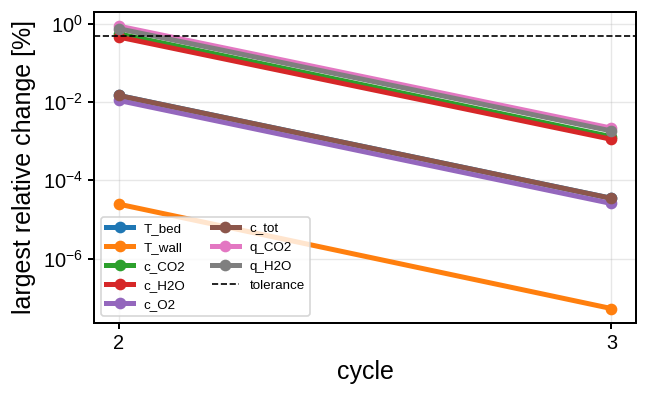

In [5]:
# Plot the largest change of each field against the cycle, with the tolerance
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for field in change:
    ax.semilogy(change.index, change[field], "o-", label=field)
ax.axhline(100 * 0.005, color="k", ls="--", lw=1, label="tolerance")
ax.set_xlabel("cycle")
ax.set_ylabel("largest relative change [%]")
ax.set_xticks(change.index)
ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()

What the check tells us:
- After cycle 2 the largest change is about 0.9 %, in the CO2 loading.
- After cycle 3 it is 0.002 %, far below the tolerance: the run stops at cycle 3.

Why so fast?
- `startup` lasts as long as `ads` (39000 s).
- So it leaves the bed close to the loading it has at the periodic state.

More cycles are needed with a shorter startup, a cycle that regenerates the bed less,\
or a tighter `execution.css_tolerance`.

## The periodic cycle at a glance

`plots_css/cycle_N/` holds the outlet of the reported cycle `N`, over the whole cycle, one figure per quantity.

Here are the CO2 mole fraction and the bed temperature at the outlet:

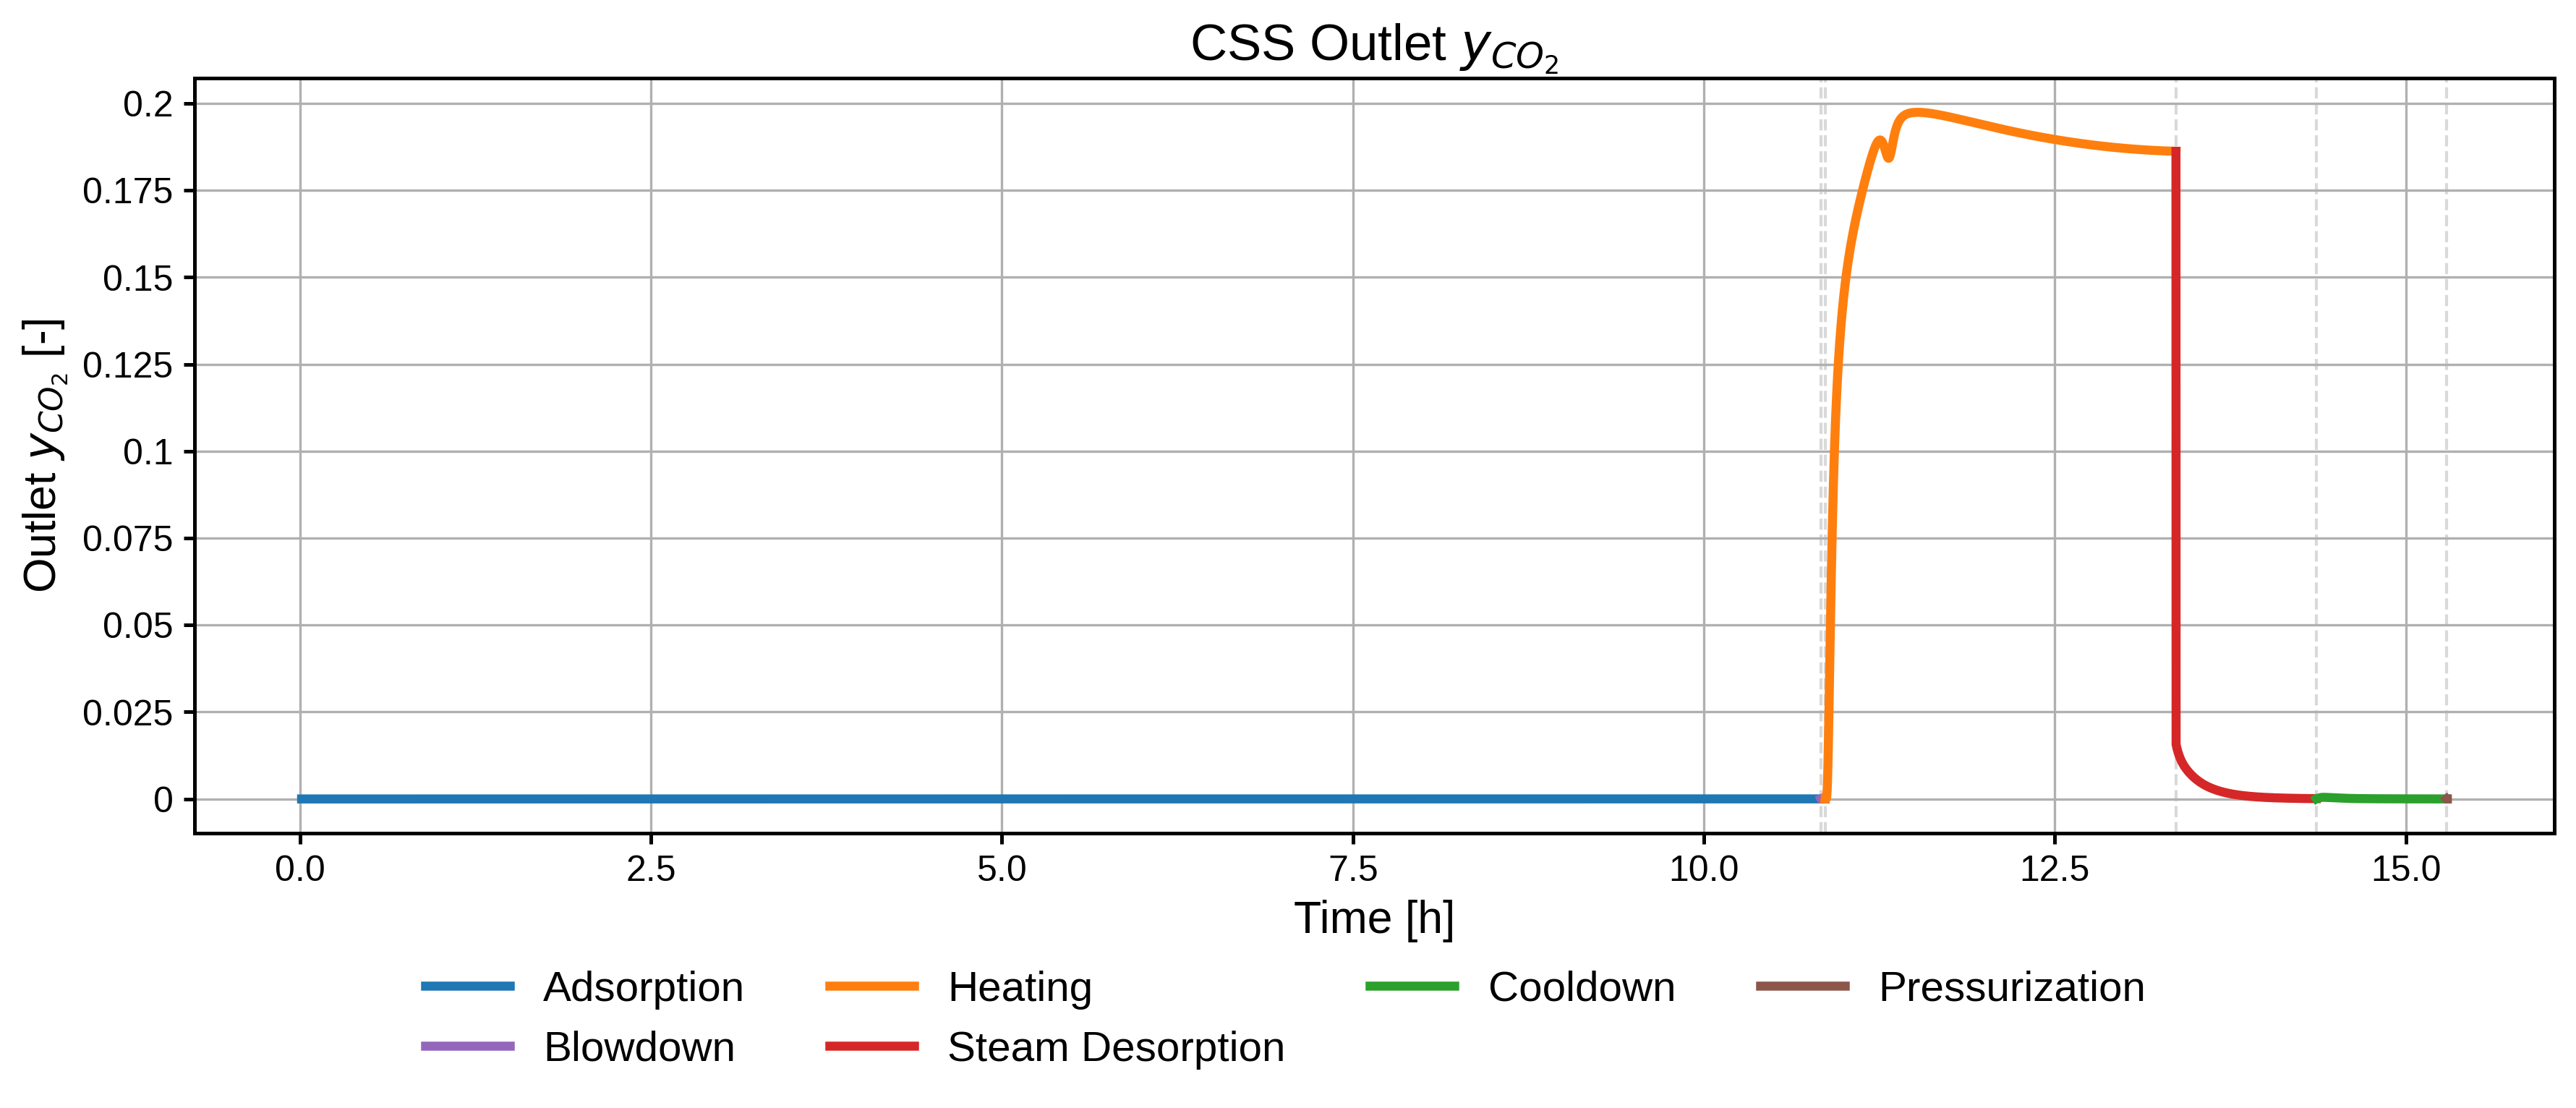

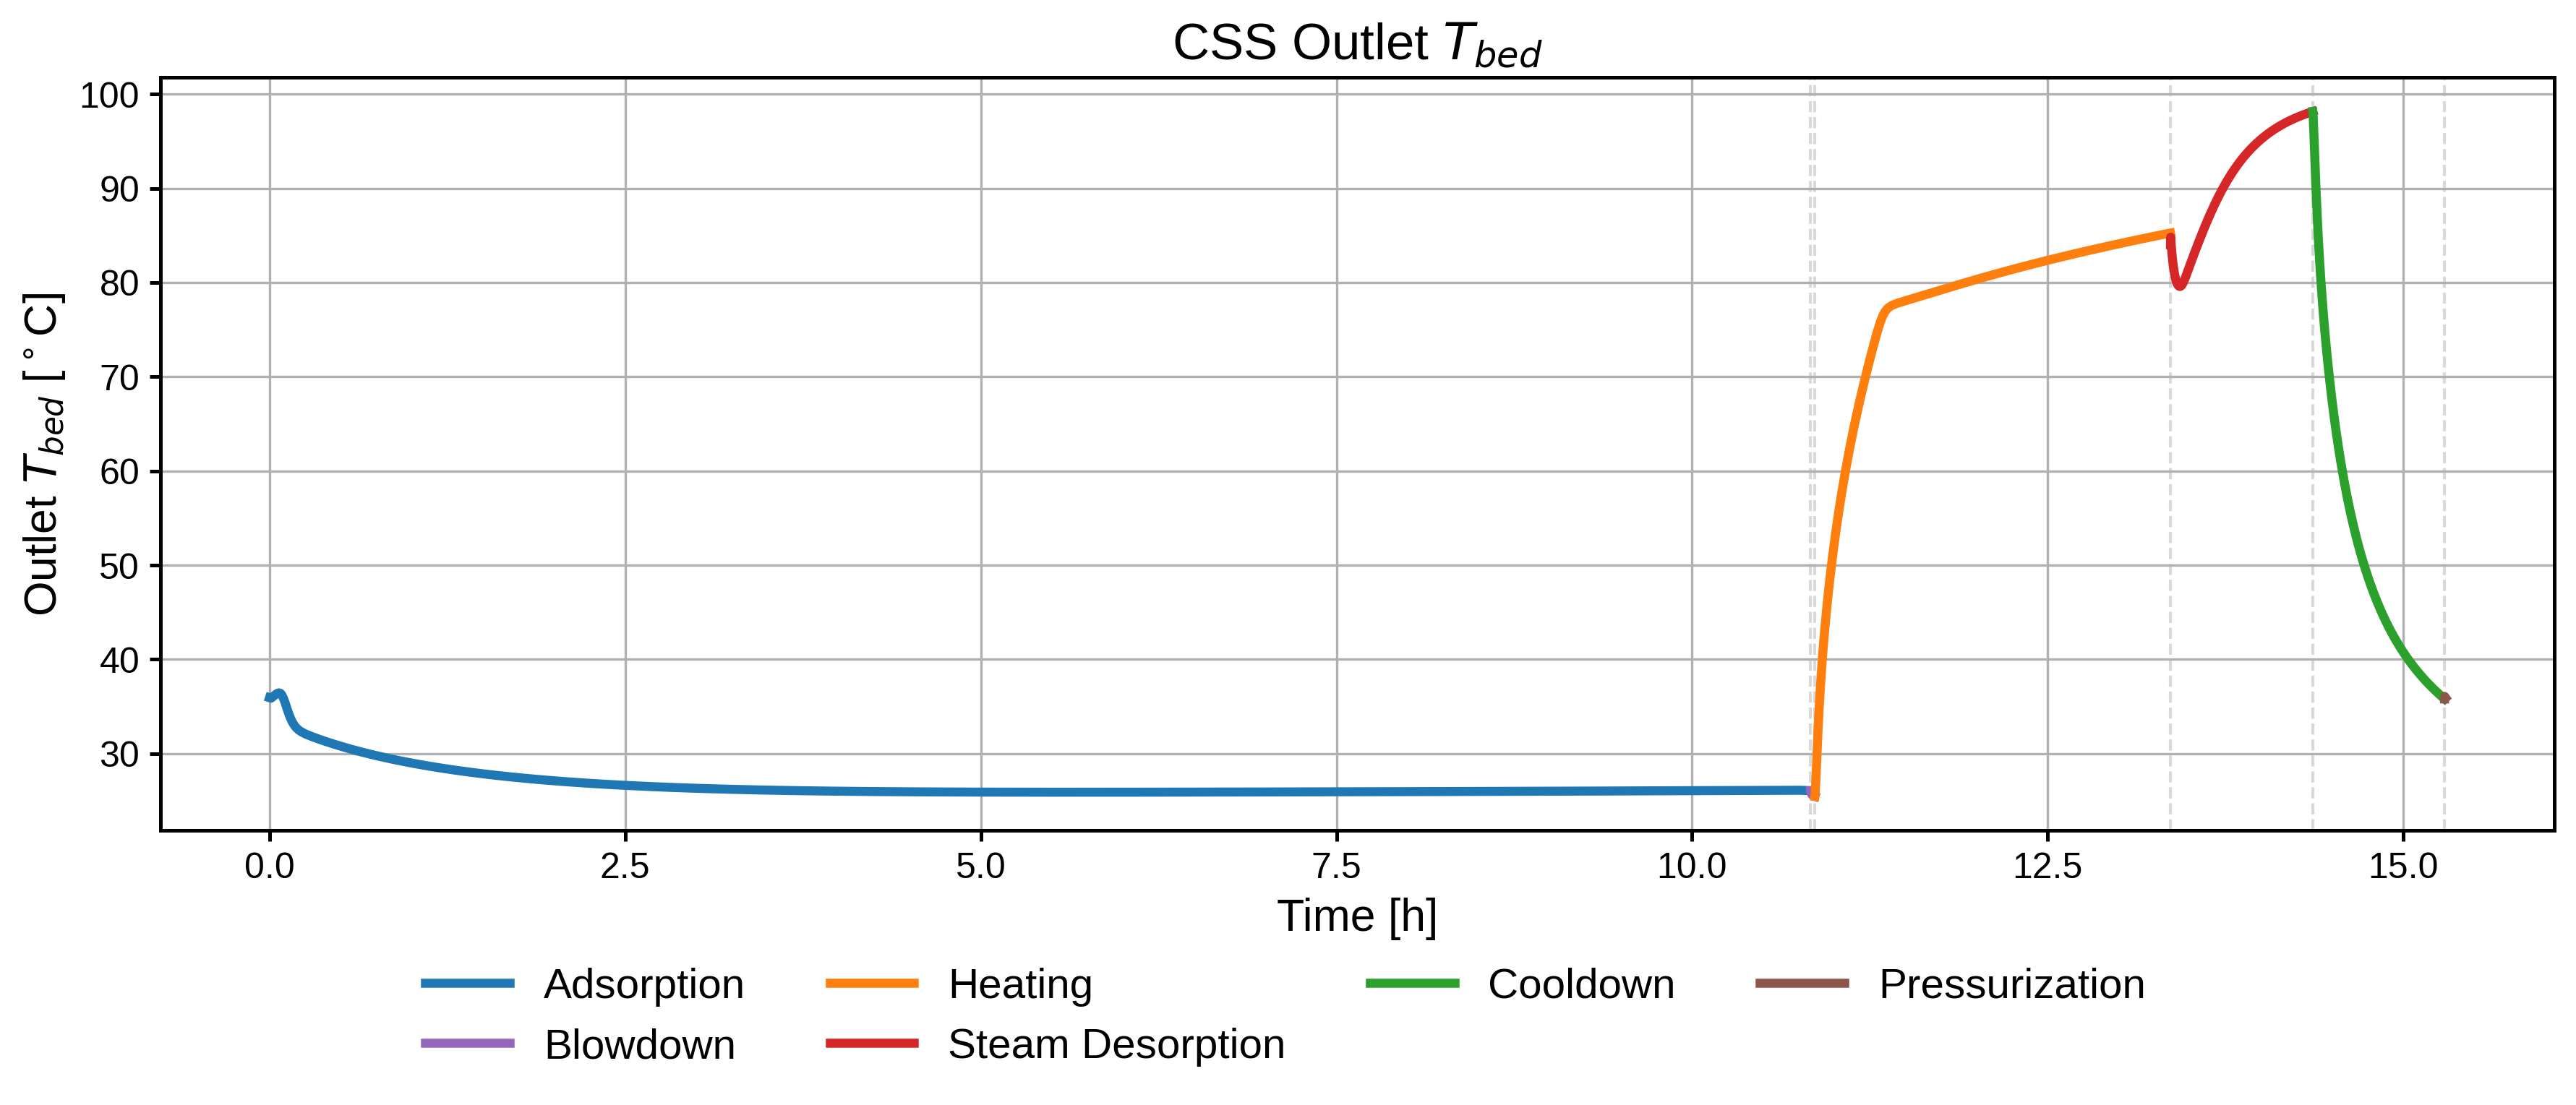

In [6]:
# Outlet CO2 mole fraction and outlet bed temperature over the reported cycle (cycle_N)
for name in ["css_outlet_y_CO2.png", "css_outlet_T_bed.png"]:
    display(Image(filename=result.results_folder / "plots_css" / f"cycle_{result.cycle}" / name, width=700))

## The KPIs of the periodic cycle

Two classes do the work:
- `CycleDataLoader` finds the simulated cycle in the run folder (the CSS cycle here);
- `CycleKPIs` computes the cycle KPIs from it, as plain numbers.

In [7]:
# Load the reported cycle and compute its KPIs
loader = pydac.CycleDataLoader(result.folder)
kpis = pydac.CycleKPIs(loader.load())
purity = kpis.purity()

# Collect the main KPIs in one table
summary = pd.Series({
    "cycle time [h]": kpis.cycle_time() / 3600,
    "CO2 recovered per cycle [g]": 1000 * kpis.recovered_mass("CO2"),
    "productivity [kg CO2 / m3 bed / day]": kpis.productivity(),
    "cyclic working capacity [mol CO2 / kg]": kpis.cyclic_working_capacity(),
    "CO2 recovery [%]": 100 * kpis.recovery(),
    "CO2 purity, wet [%]": 100 * purity["purity_wet"],
    "CO2 purity, dry [%]": 100 * purity["purity_dry"],
    "equivalent work [kWh / kg CO2]": kpis.equivalent_work() / 3.6,
    "steam / CO2 [kg / kg]": kpis.steam_to_co2_ratio(),
}, name=loader.cycle_label)
summary.round(3)

cycle time [h]                             15.296
CO2 recovered per cycle [g]                18.489
productivity [kg CO2 / m3 bed / day]       29.009
cyclic working capacity [mol CO2 / kg]      1.382
CO2 recovery [%]                           65.894
CO2 purity, wet [%]                        96.833
CO2 purity, dry [%]                       100.000
equivalent work [kWh / kg CO2]             24.354
steam / CO2 [kg / kg]                     194.710
Name: cycle_3, dtype: float64

What each KPI means:
- **Productivity**: CO2 recovered per cubic metre of bed and per day of cycle.
- **Cyclic working capacity**: the CO2 the sorbent takes up and gives back in one cycle, per kg of sorbent.
- **Recovery**: the recovered CO2, as a fraction of the CO2 adsorbed in `ads`.
- **Purity**: the CO2 mole fraction of the product, with its water (wet) and without (dry).
- **Equivalent work**: the energy the cycle needs, as electricity, per kg of recovered CO2:
  - compression and vacuum as they are;
  - the heat of the jacket and of the steam, at the work it could have produced (Carnot);
  - the condenser cooling below the cooling-water temperature, through a chiller;
  - cooling water itself costs nothing.

How each KPI is computed: [06 Post-processing](../../docs/manual/06_post_processing.md).

The time of each step:

In [8]:
# Duration of each step of the reported cycle
kpis.cycle_time_breakdown().round(3)

,Step,Duration [s],Fraction [-],Cumulative time [s]
0,adsorption,39000.000,0.708,39000.000
1,blowdown,106.644,0.002,39106.644
2,preheating,9000.000,0.163,48106.644
3,desorption,3600.000,0.065,51706.644
4,cooldown,3335.002,0.061,55041.646
5,pressurization,25.340,0.000,55066.986


## Where the CO2 goes

`mass_change_table()` gives the change of each species in the column, step by step\
(positive: the column took it up).

In [9]:
# CO2 change in the column, step by step, in grams
co2 = 1000 * kpis.mass_change_table()["CO2"]
co2.name = "CO2 change in the column [g]"
co2.round(3)

Step
adsorption        28.059
blowdown           0.000
preheating        -6.885
desorption       -21.174
cooldown           0.000
pressurization     0.000
Name: CO2 change in the column [g], dtype: float64

In [10]:
# The CO2 balance of one cycle, in grams
vented = 1000 * kpis.vented_mass()
desorbed = -co2["desorption"]
recovered = 1000 * kpis.recovered_mass("CO2")
print(f"adsorbed in ads                  {co2['adsorption']:6.2f} g")
print(f"vented with the heat gas         {vented:6.2f} g")
print(f"leaving the column in s_des      {desorbed:6.2f} g")
print(f"  of which recovered as product  {recovered:6.2f} g")
print(f"  dissolved in the condensate    {desorbed - recovered:6.2f} g")

adsorbed in ads                   28.06 g
vented with the heat gas           6.89 g
leaving the column in s_des       21.17 g
  of which recovered as product   18.49 g
  dissolved in the condensate      2.68 g


What the balance tells us:
- **`ads`** takes up about 28 g of CO2 per cycle.
- **Wall heating** releases about 7 g of it, a quarter.
  - `heat` vents its gas, so that CO2 is lost.
- **`s_des`** releases the other 21 g.
  - Its outlet goes through a condenser at 5 °C, which removes the steam.
  - About 2.7 g of CO2 dissolves in the 3.6 kg of condensed water.
  - The remaining 18.5 g is the product: a recovery of 66 %.
- **Blowdown, cooling and pressurization** move almost no CO2.

## Where the energy goes

`equivalent_work_breakdown()` splits the equivalent work by step and by utility,\
in kWh of electricity per kg of recovered CO2:

In [11]:
# Equivalent work by step and by utility [kWh / kg CO2]
work = kpis.equivalent_work_breakdown()
work.round(3)

,Compression,Vacuum,Jacket,Steam,Condenser
Step,,,,,
adsorption,0.303,0.000,0.000,0.000,0.00
blowdown,0.000,0.001,0.000,0.000,0.00
preheating,0.000,0.117,0.422,0.000,0.00
desorption,1.369,0.048,0.017,21.027,1.05
cooldown,0.000,0.000,0.000,0.000,0.00
pressurization,0.000,0.000,0.000,0.000,0.00


Let's look at the same breakdown as a figure.
- The run already drew it, together with all the other KPI figures, in `kpis/png/` of the run folder\
  (`kpis/pdf/` with `execution.plot_format = "pdf"`).
- There you also find the mass changes, the thermal and electrical energy, the product composition, and more.
- Here we show only this one, for convenience.


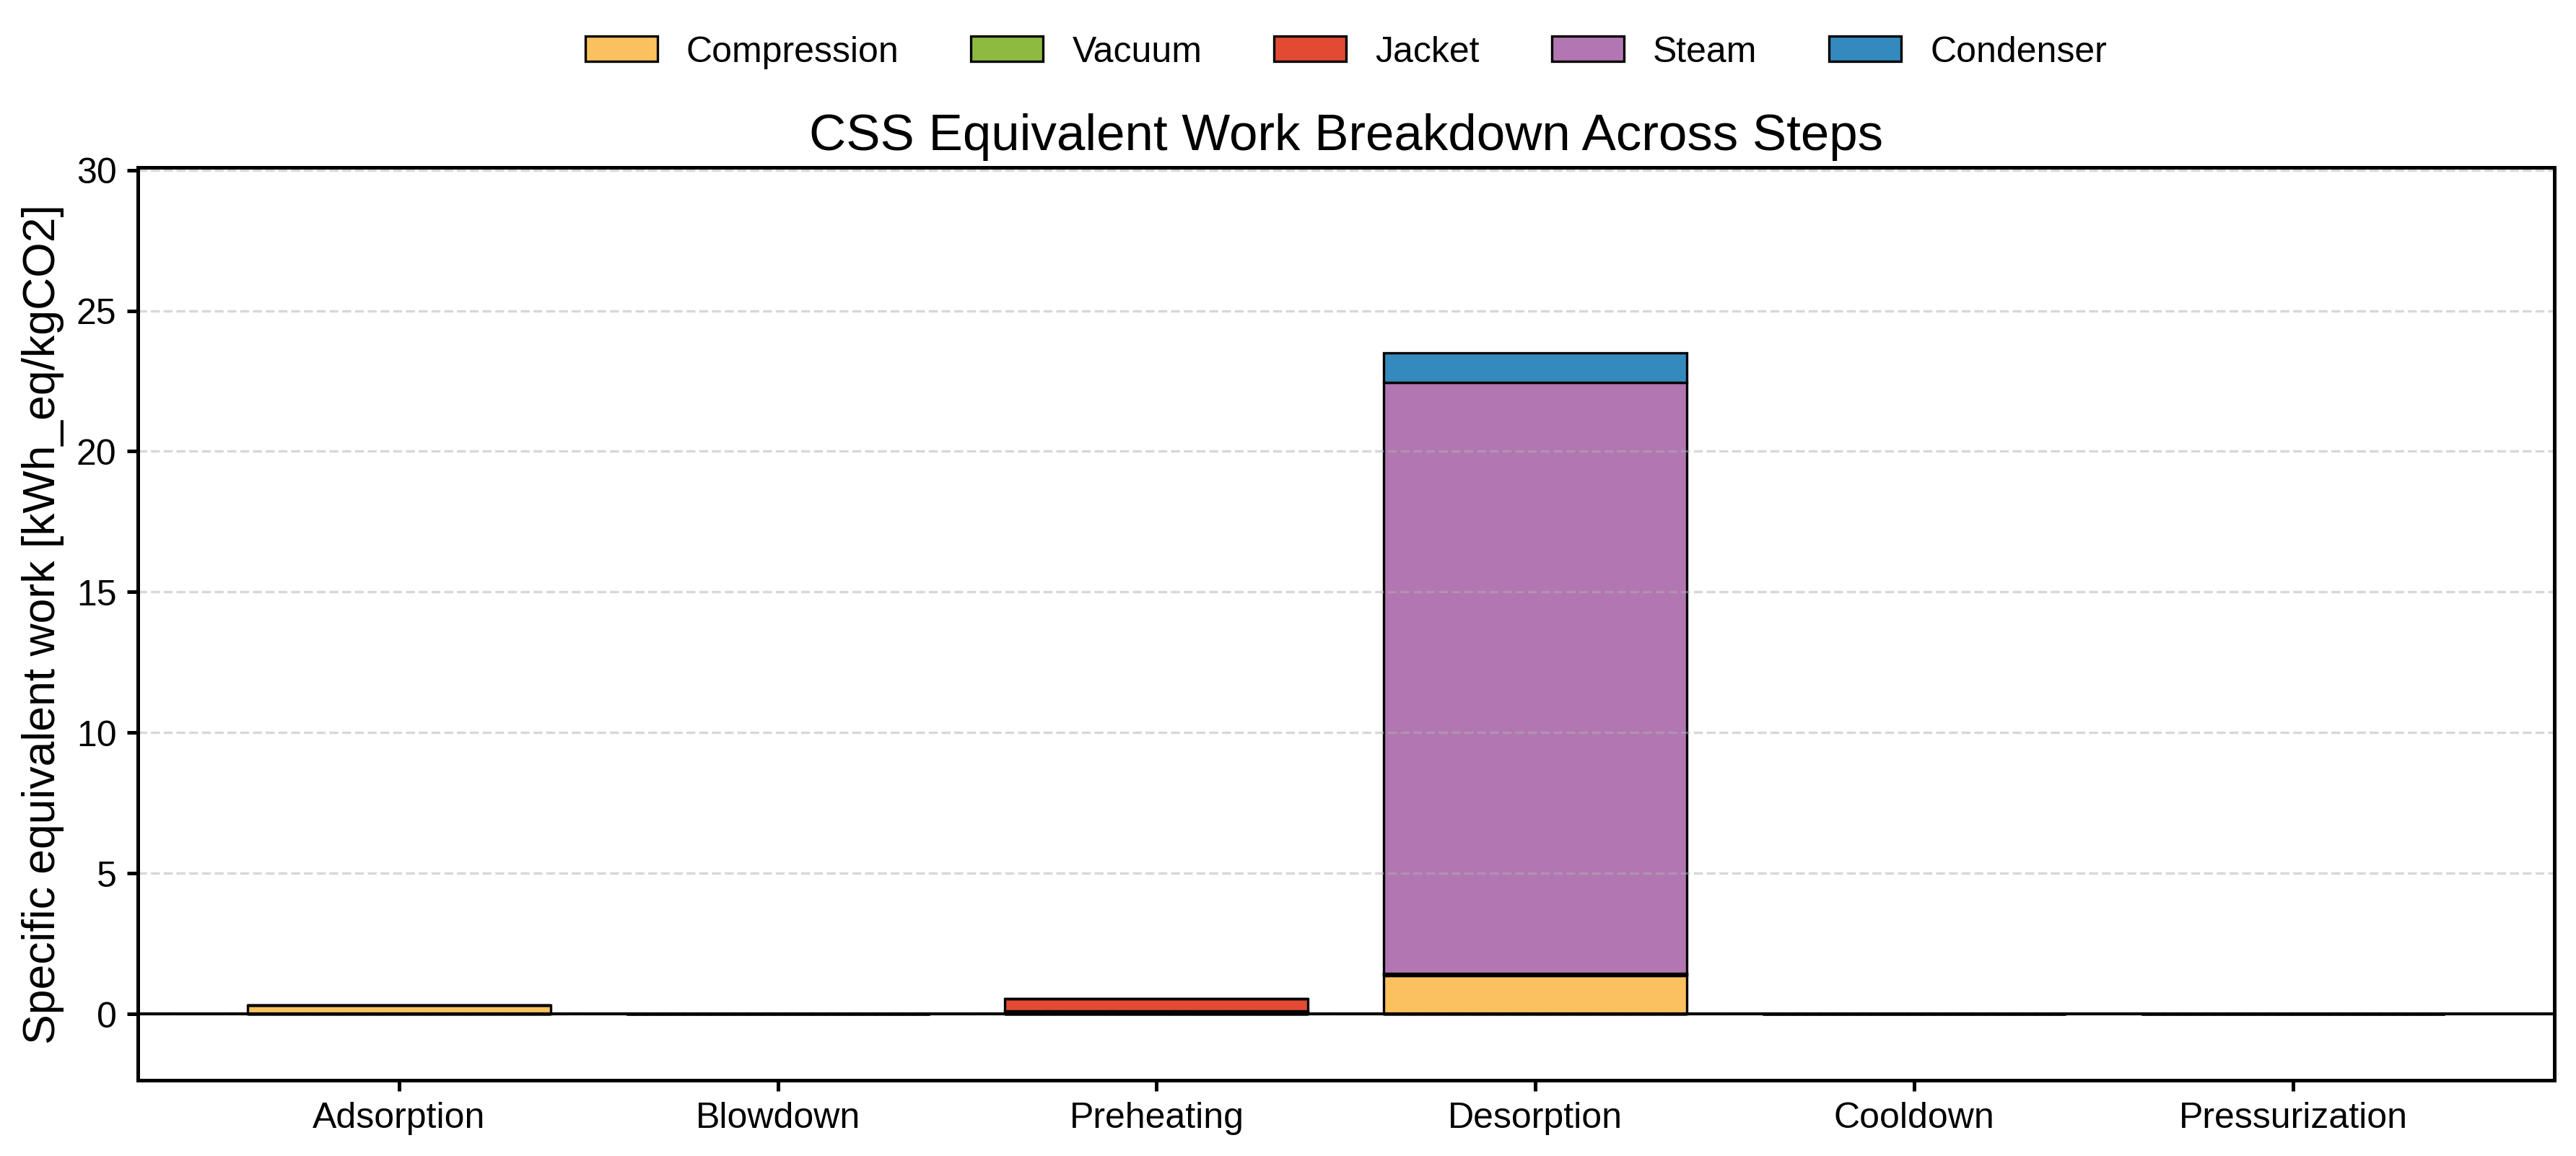

In [12]:
# The same breakdown, as the figure the run wrote in kpis/png/
display(Image(filename=result.results_folder / "kpis" / "png" / f"{loader.cycle_label}_css_equivalent_work_breakdown_specific.png", width=650))

Steam dominates: about 21 of the 24 kWh per kg of CO2.
- `s_des` feeds 1 g/s of steam for one hour: 3.6 kg.
- It recovers 18.5 g of CO2.
- That is about 195 kg of steam per kg of CO2.

The built-in case is a reference to run, not a design.\
Less steam, shorter steps or more wall heating will definitely change these numbers.\
[Tutorial 05](05_nsga2_trial.ipynb) searches for better settings with an optimizer.

## Inside the bed

With `plot_final_cycle_profiles`, every step of the reported cycle has its profile plots in `cycle_N/STEP/profiles/`.\
Among them: 2D maps over the length and the radius of the column, at six times of the step.
- The two `heat` maps use the times we asked for in the run cell (`snapshot_times`).
- Any step and field works the same way: [Times of the step plots](../../docs/guide/04_running.md#times-of-the-step-plots).

Here are the bed temperature and the CO2 loading during `heat`, and the CO2 loading during `s_des`:

**Bed temperature during heat [°C]**

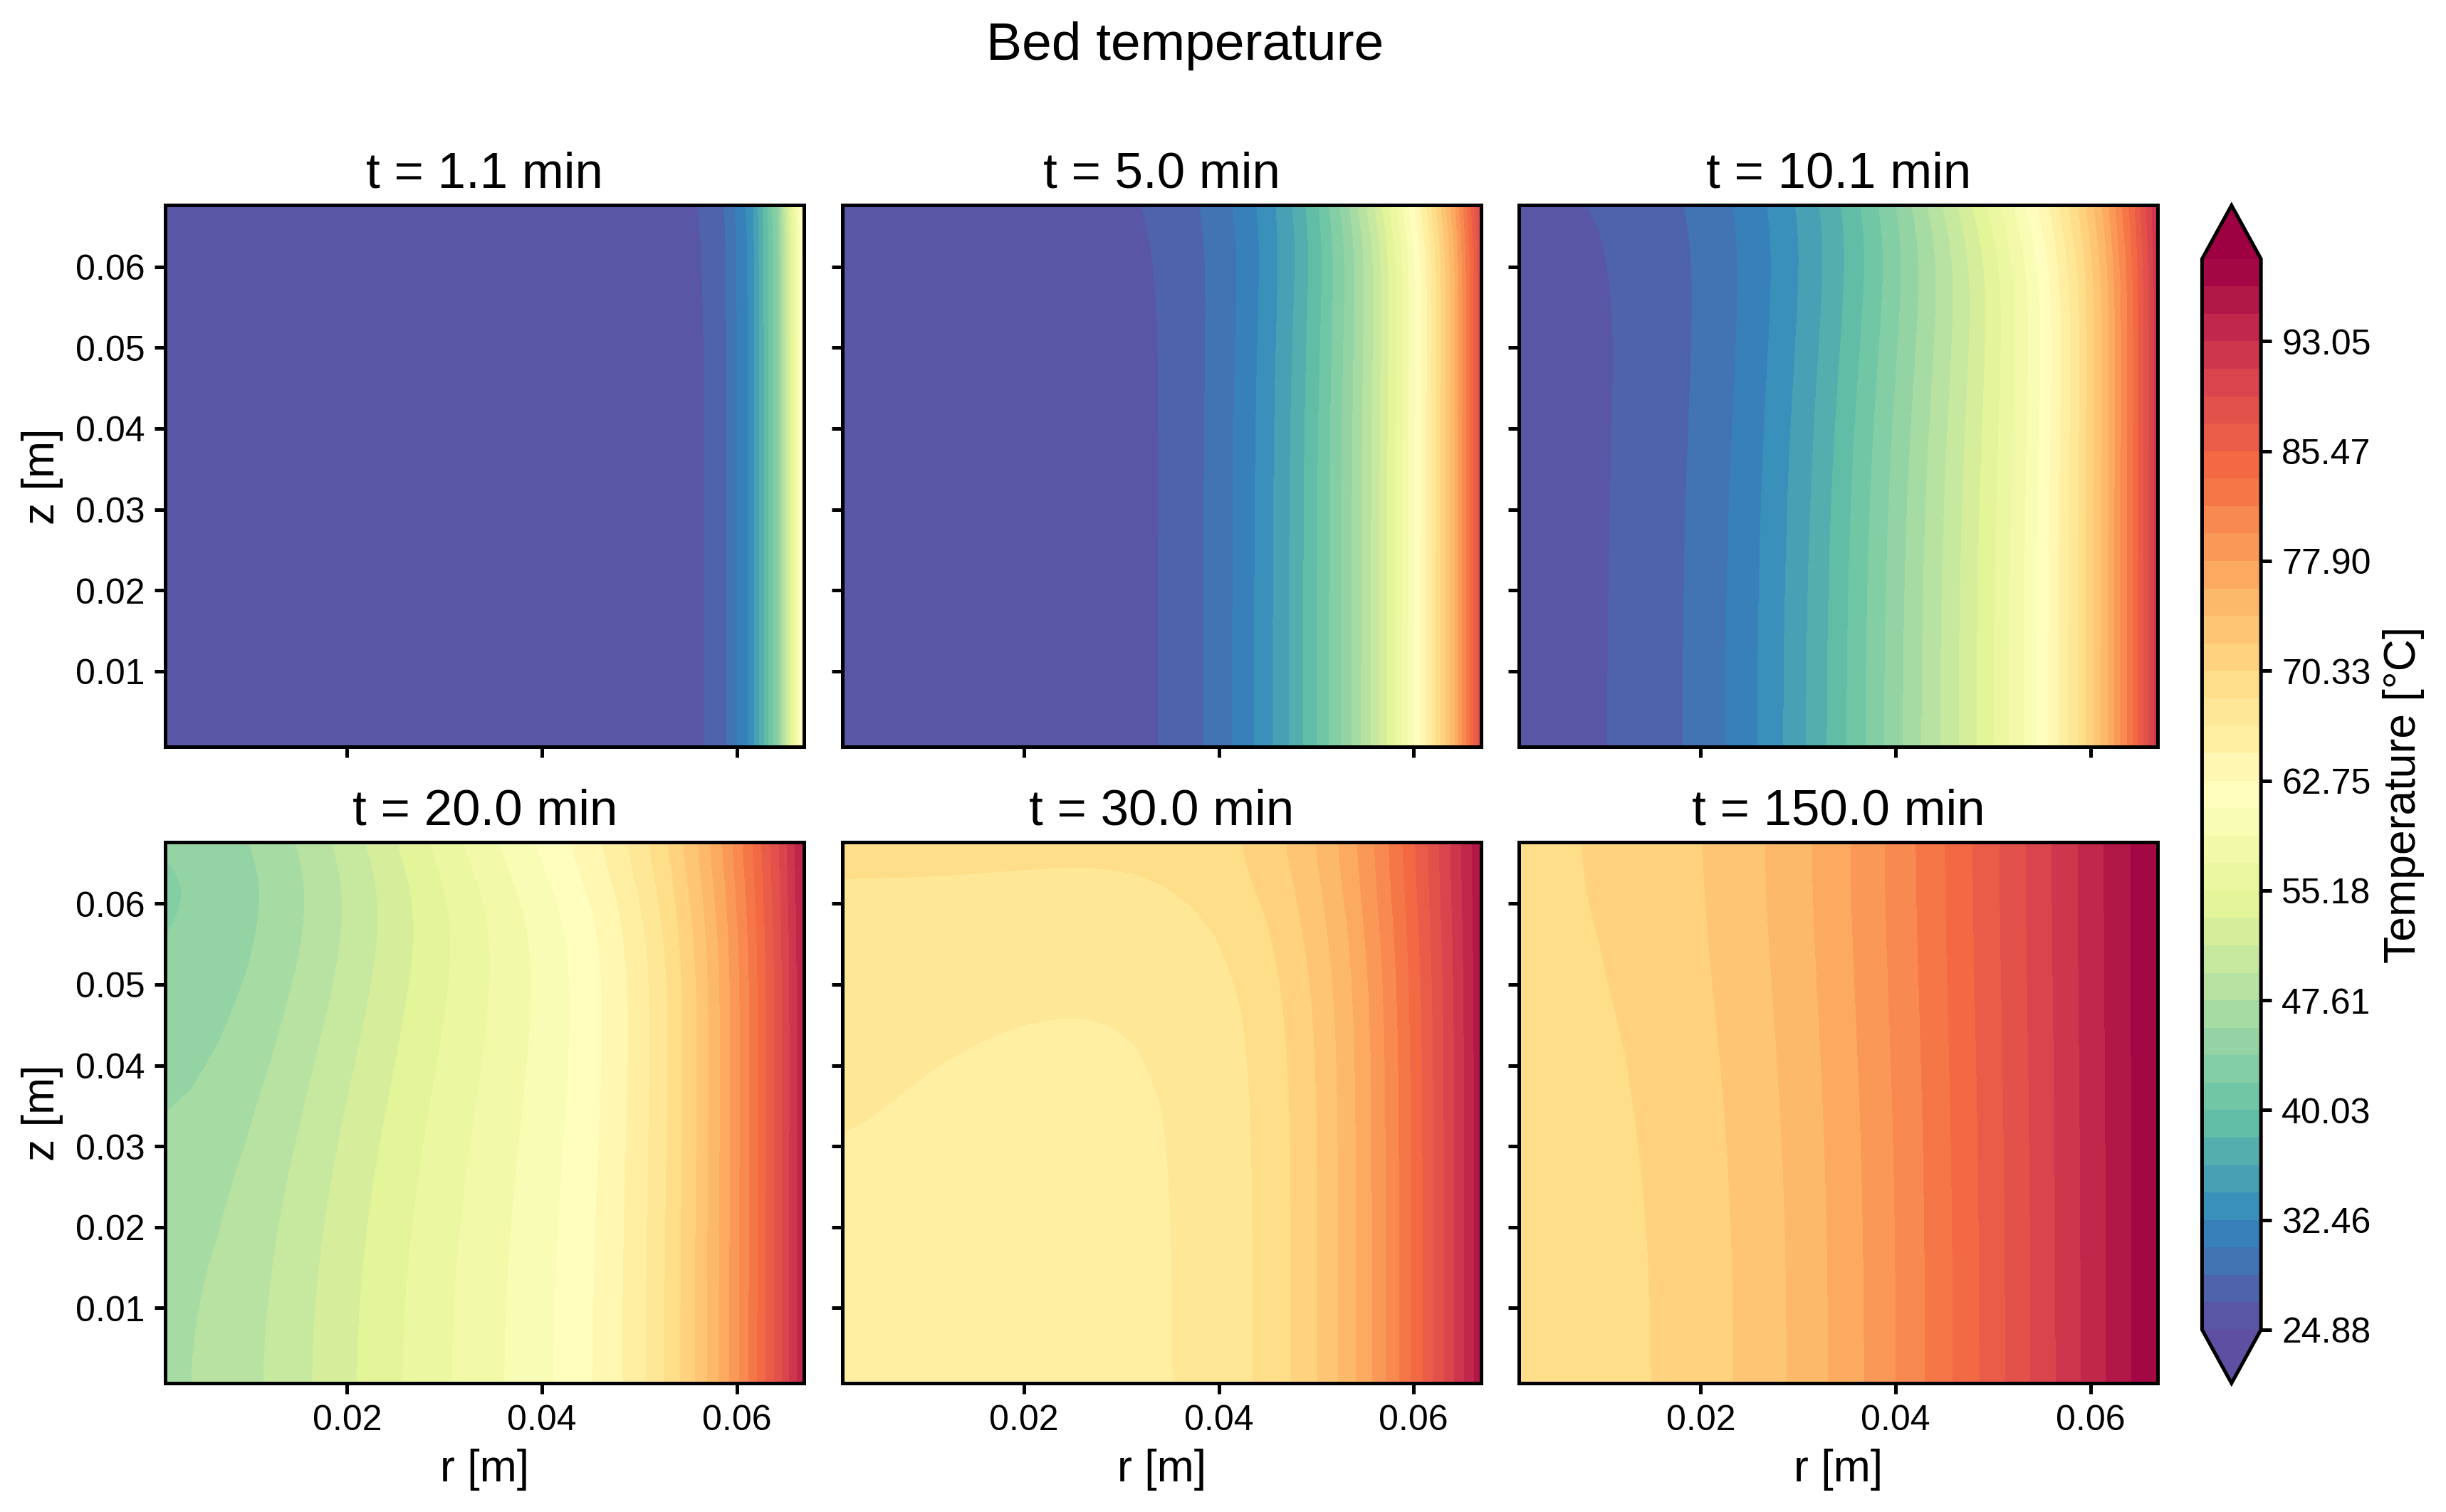

**Solid-phase CO2 loading during heat [mol/kg]**

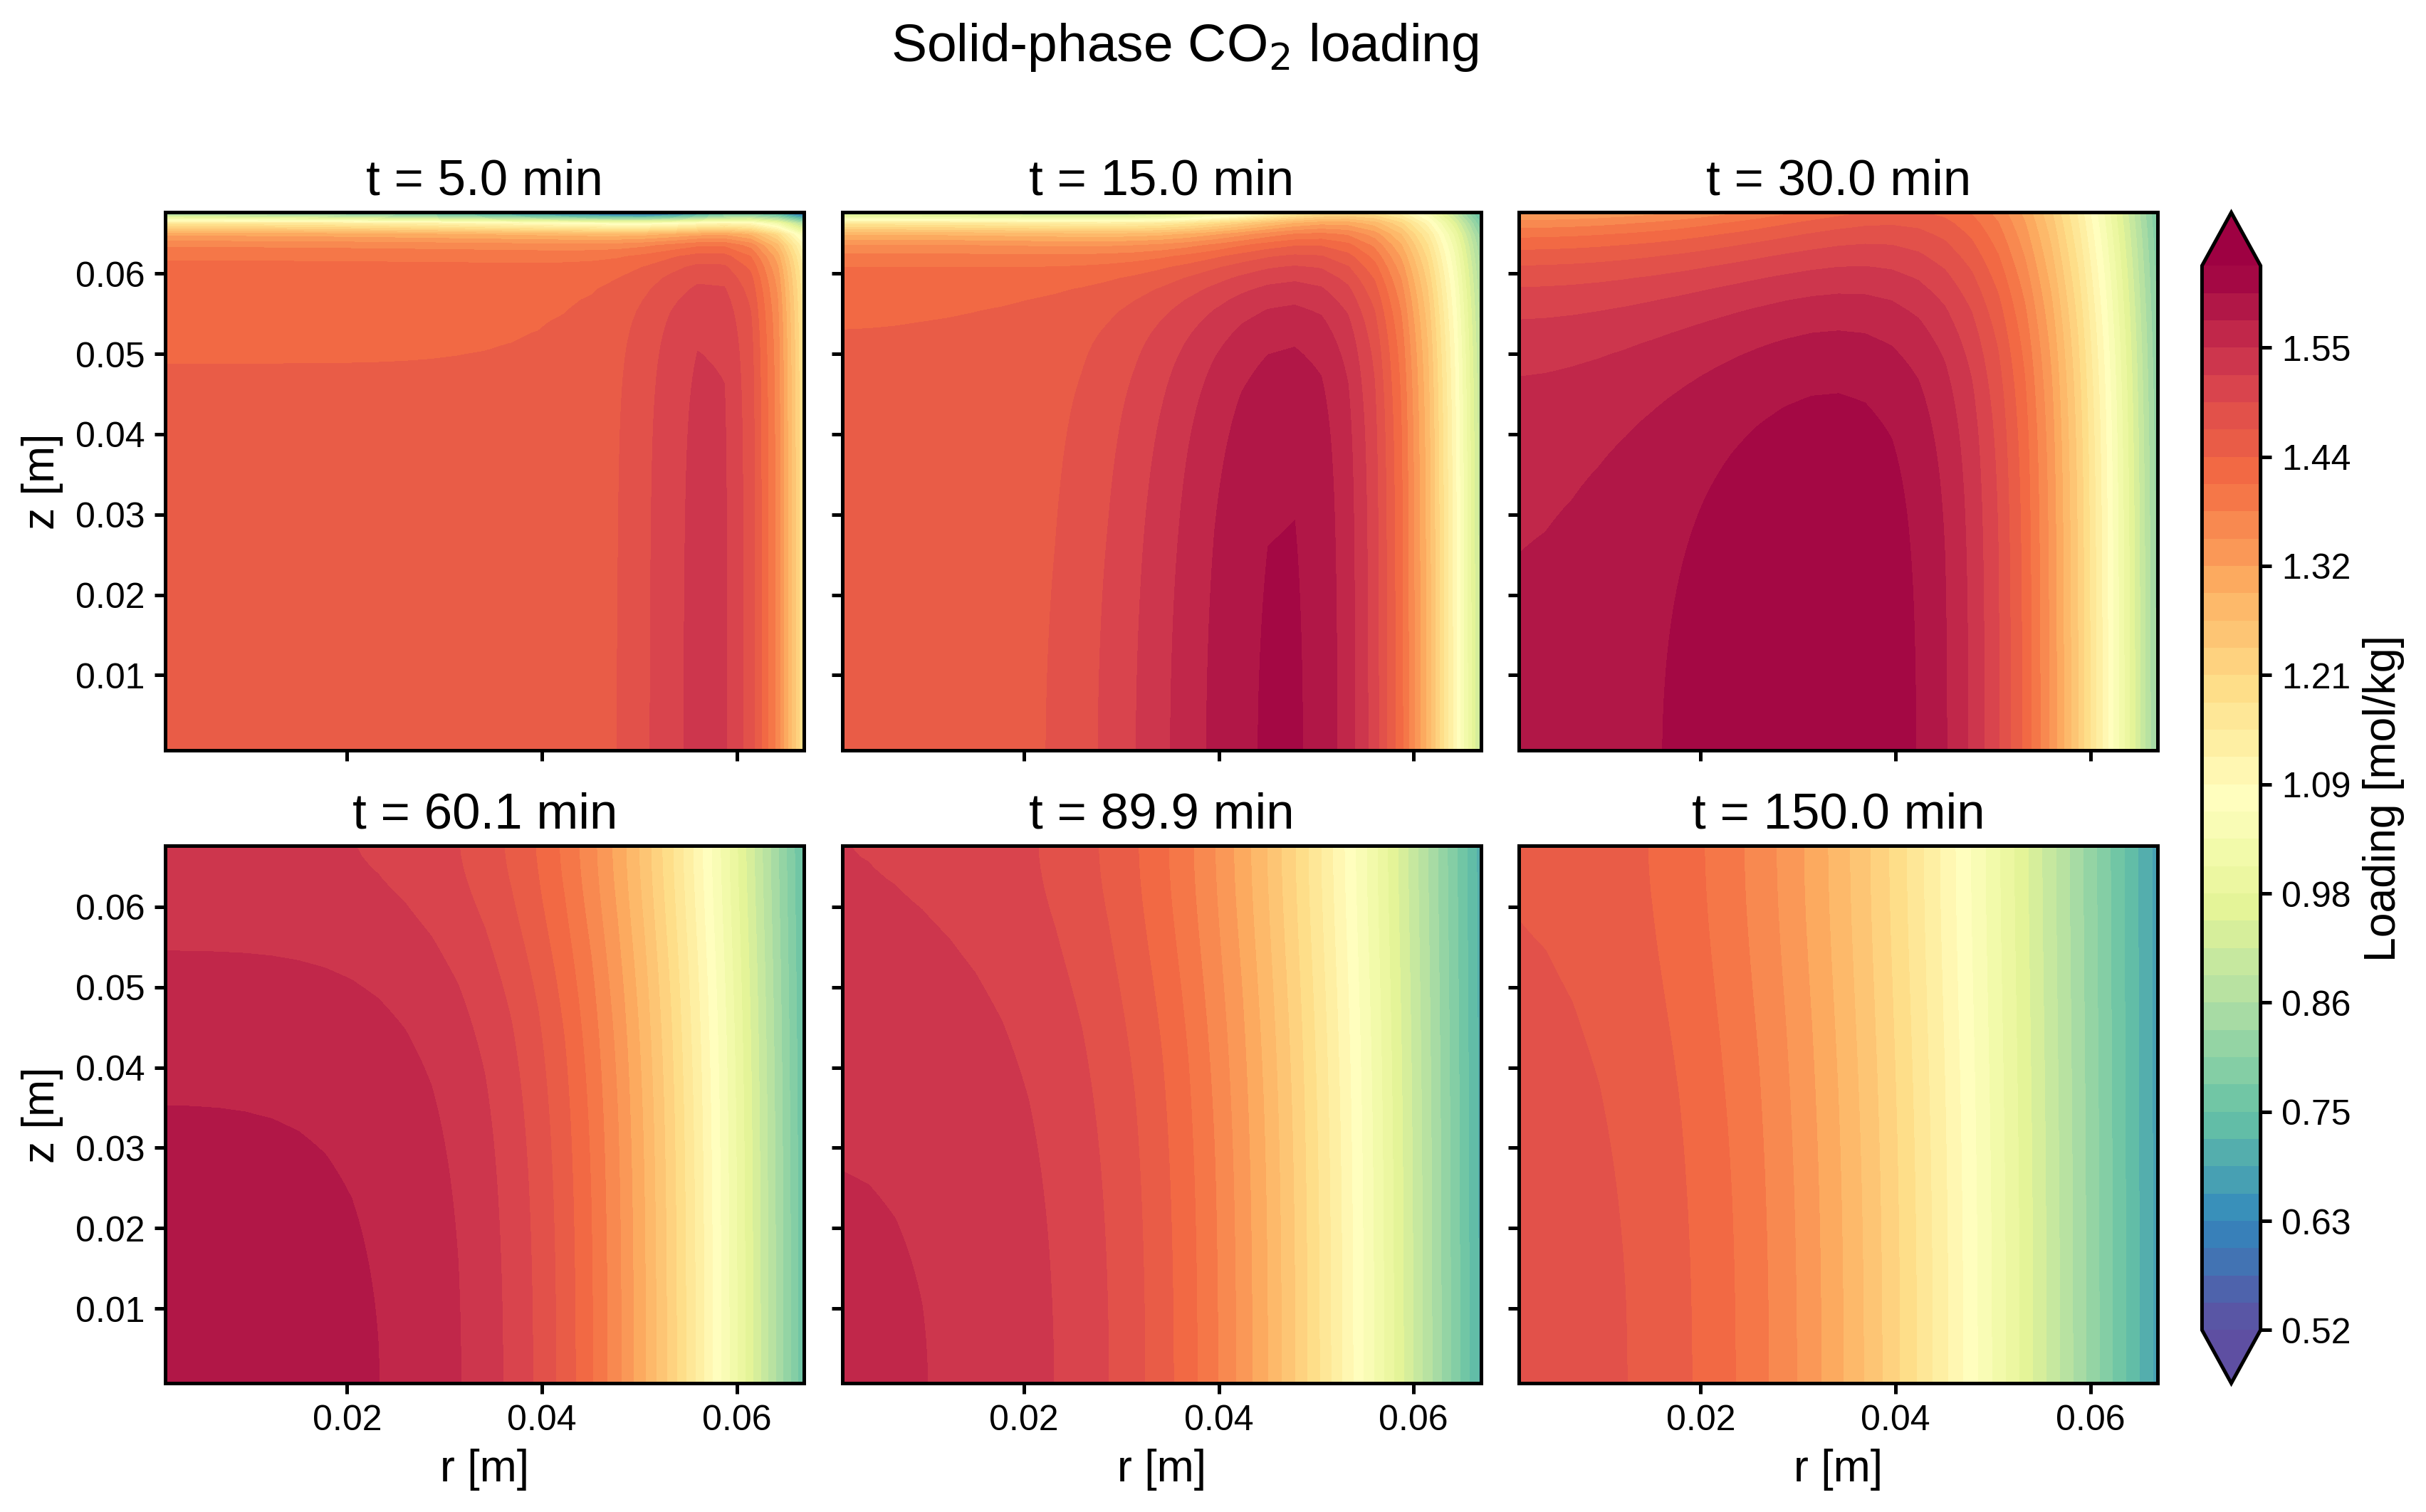

**Solid-phase CO2 loading during s_des [mol/kg]**

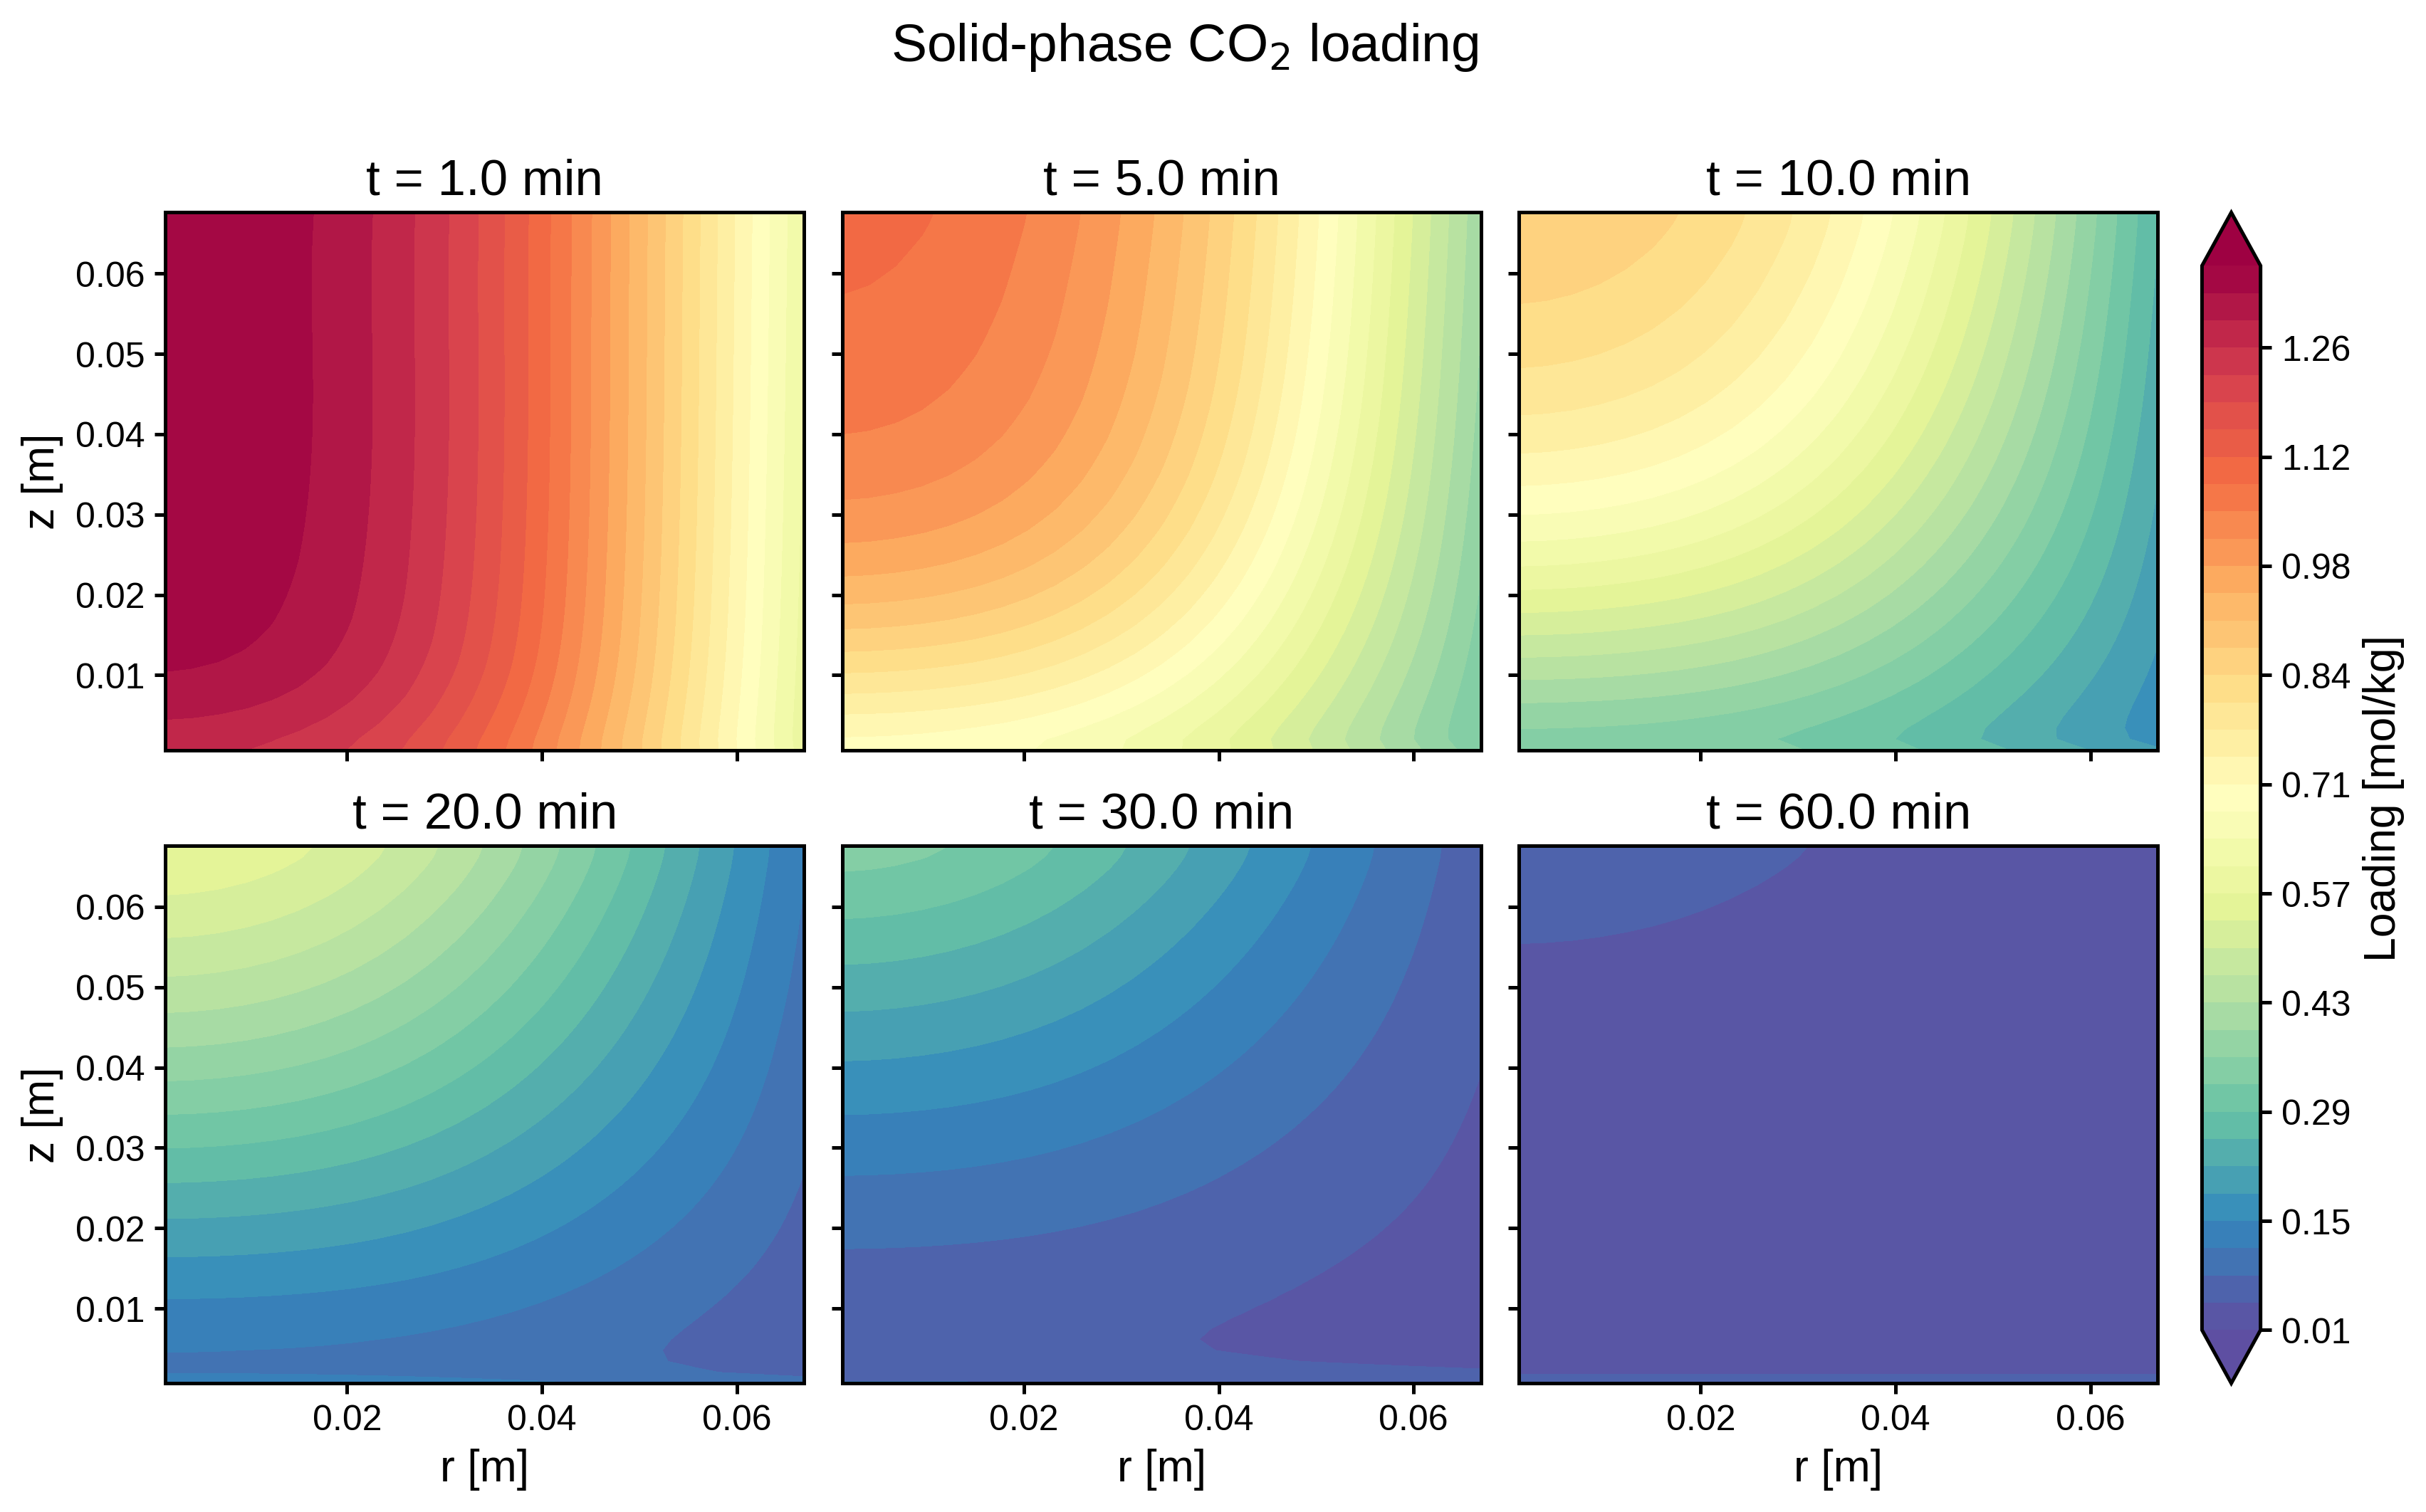

In [13]:
# The folder of the reported cycle, and three of its 2D maps
cycle = result.results_folder / loader.cycle_label
maps = [
    ("Bed temperature during heat [°C]", "heat/profiles/internal_2D_profiles/heat_Tbed_2D_snapshots.png"),
    ("Solid-phase CO2 loading during heat [mol/kg]", "heat/profiles/internal_2D_profiles/heat_qCO2_2D_snapshots.png"),
    ("Solid-phase CO2 loading during s_des [mol/kg]", "s_des/profiles/internal_2D_profiles/s_des_qCO2_2D_snapshots.png"),
]
for label, path in maps:
    display(Markdown(f"**{label}**"))
    display(Image(filename=cycle / path, width=700))

What the maps show:
- **Bed temperature in `heat`**: the heat enters at the wall (on the right of each map).
  - After one minute only a thin layer next to the wall is warm.
  - The warm front reaches the axis in 20 to 30 minutes.
  - Then the bed warms slowly: after two and a half hours the wall layer is above 90 °C, the axis still below 70 °C.
- **CO2 loading in `heat`**: the sorbent near the wall releases its CO2, and the gas vents it.
  - Part of that CO2 is taken up again by the colder bed further in: a band of higher loading moves towards the axis.
  - Around 30 minutes the core holds more CO2 than at the start of `heat`: about 1.6 mol/kg against 1.4.
  - Only then does the core start to release it.
- **CO2 loading in `s_des`**: the steam enters at the bottom (z = 0) and sweeps the column upwards.
  - When the steam starts, the sorbent near the wall has already lost about half of its CO2, while the core is still loaded.
  - The last CO2 leaves from the top of the axis; after an hour the bed is regenerated.

A 1D model averages these radial differences away ([tutorial 04](04_1d_vs_2d.ipynb)).

## The KPI report files

The run writes the KPI report of the reported cycle into `kpis/`:
- a summary, as text and JSON;
- the tables, as CSV under `csv/`;
- the figures under `png/` (the folder of `execution.plot_format`).

The summary:

In [14]:
# Print the text summary of the KPI report
print((result.results_folder / "kpis" / f"{loader.cycle_label}_css_kpi_summary.txt").read_text())

                             CSS KPI Summary - cycle_3                              

                                   Metric       Value         Unit
                              Cycle label     cycle_3            -
                               Cycle time  917.783099          min
                               Bed volume       0.001           m3
                     Solid adsorbent mass      461.28            g
               CO2 adsorbed in adsorption   28.058828            g
               CO2 desorbed in desorption   21.173751            g
     CO2 recovered after vacuum discharge   18.489009            g
               H2O adsorbed in adsorption   18.668202            g
               H2O desorbed in desorption     6.78413            g
     H2O recovered after vacuum discharge    0.247522            g
              Saturation after adsorption   97.760896            %
              Saturation after desorption    1.621951            %
              CO2 cyclic working capacity  

## The oxygen check

Why it matters:
- Amine sorbents degrade when they are hot in the presence of oxygen.
- Wall heating under vacuum is meant to remove the O2 before the bed gets hot.

What pyDAC does, at the end of every CSS run:
- on the saved samples of the reported cycle, it checks whether any point of the bed was above 90 °C\
  while its gas still held oxygen (above a numerical floor of 1e-6 ppm);
- it prints the result;
- it writes it to `kpis/csv/process/oxygen_hot_bed_check.csv`.

It is a check on the results only:
- it does not stop or change the run;
- it is not a model of how the sorbent ages.

In [15]:
# Read the result of the oxygen check
pd.read_csv(result.results_folder / "kpis" / "csv" / "process" / "oxygen_hot_bed_check.csv")

,condition_met,step,point,time_s
0,True,heat,"z_index=49,r_index=24 (z=0.99,r=0.98)",297.297297


The condition is met:
- about five minutes into `heat`, the cell next to the wall at the outlet end passes 90 °C;
- some O2 is still in its gas;
- `z` and `r` are fractions of the length and the radius.

The check reports the first saved sample where it happens.\
[Tutorial 04](04_1d_vs_2d.ipynb) shows that a 1D model misses it.

## Write the report again, from the saved run

The *report* of a run is the set of all result files that the run writes at its end, from the saved solution of the reported cycle:
- the outlet plots of the cycle, in `plots_css/cycle_N/`;
- the KPI summary (text and JSON), the KPI tables (CSV) and the KPI figures, in `kpis/`;
- the oxygen check.

`pydac.report(folder)` allows you to write these files again.
- It solves nothing: it reads the saved results, so it takes seconds, not a new CSS run.
- It does not change the saved solution.
- It draws the step plots (the 2D maps above) again only if you ask, with `snapshot_times`.

When is it useful?
- **Another figure format.** The run wrote PNG files, handy in a notebook. A paper wants PDF (vector figures).\
  `fmt="pdf"` writes the same figures again as PDF, next to the PNG ones.
- **Another cycle.** `cycle=2` reports cycle 2 instead of the last CSS cycle, if its folder is still there\
  (not with `execution.keep_only_final_cycle`).
- **A run without its report.** A run with `execution.generate_kpi_outputs` or `execution.plot_cyclic_profiles` set to false\
  (a bit faster) gets the missing files later.
- **A report that failed.** If writing the report fails at the end of a run, the run is kept: fix the cause, then call `report`.
- **Other times for the 2D maps.** `snapshot_times` draws the step plots of the cycle again, with your times.\
  Each step is reloaded from its saved solution, not solved: about a minute here.

First, the figures of the CSS cycle again, as PDF (the cell also prints the KPI summary again):

In [16]:
# Write the report of the CSS cycle again, with the figures as PDF: nothing is solved
pydac.report(result.folder, fmt="pdf")

# The KPI figures, now also as PDF (the PNG ones are still in kpis/png/)
sorted(path.name for path in (result.results_folder / "kpis" / "pdf").iterdir())

Run folder: /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db
Post-processing cycle 3.
[CyclicProfiles] Mixed-cup outlet average had zero denominator; falling back to radial average for those points.


[Saved] /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/plots_css/cycle_3/css_outlet_y_CO2.pdf
[Saved] /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/plots_css/cycle_3/css_outlet_y_H2O.pdf
[Saved] /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/plots_css/cycle_3/css_outlet_y_O2.pdf
[Saved] /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/plots_css/cycle_3/css_outlet_y_N2.pdf
[Saved] /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/plots_css/cycle_3/css_outlet_q_CO2.pdf
[Saved] /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/plots_css/cycle_3/css_outlet_q_H2O.pdf
[Saved] /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packe

['cycle_3_css_electrical_energy_breakdown.pdf',
 'cycle_3_css_equivalent_work_breakdown_specific.pdf',
 'cycle_3_css_equivalent_work_conditions.pdf',
 'cycle_3_css_mass_changes_co2_h2o.pdf',
 'cycle_3_css_mass_changes_n2_o2.pdf',
 'cycle_3_css_mass_changes_percent_of_adsorption.pdf',
 'cycle_3_css_process_kpis_overview.pdf',
 'cycle_3_css_product_composition.pdf',
 'cycle_3_css_residual_gas_ppm_n2_o2.pdf',
 'cycle_3_css_thermal_energy_breakdown.pdf']

Then a 2D map with other snapshot times: the bed temperature during `cool`.
- pyDAC spaces its six times evenly over the step: 0, 11, 22, 33, 44 and 56 min.
- But the bed starts to cool at the wall in the first minutes, and those times skip it.
- So we ask for 0, 2, 5, 10, 20 and 55 min.
- `report` draws the plots of *every* step again: a step or field you do not list goes back to the default times.\
  So we also pass the `heat` times of the run, to keep the two `heat` maps as they were.

The cell prints the log of the replay: every step of the cycle is reloaded, one after the other.

Run folder: /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db
Post-processing cycle 3.
[CyclicProfiles] Mixed-cup outlet average had zero denominator; falling back to radial average for those points.
[Saved] /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/plots_css/cycle_3/css_outlet_y_CO2.png
[Saved] /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/plots_css/cycle_3/css_outlet_y_H2O.png
[Saved] /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/plots_css/cycle_3/css_outlet_y_O2.png
[Saved] /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/plots_css/cycle_3/css_outlet_y_N2.png
[Saved] /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db/2D_mode/plots_css/cycle_3/css_outlet_q_CO2

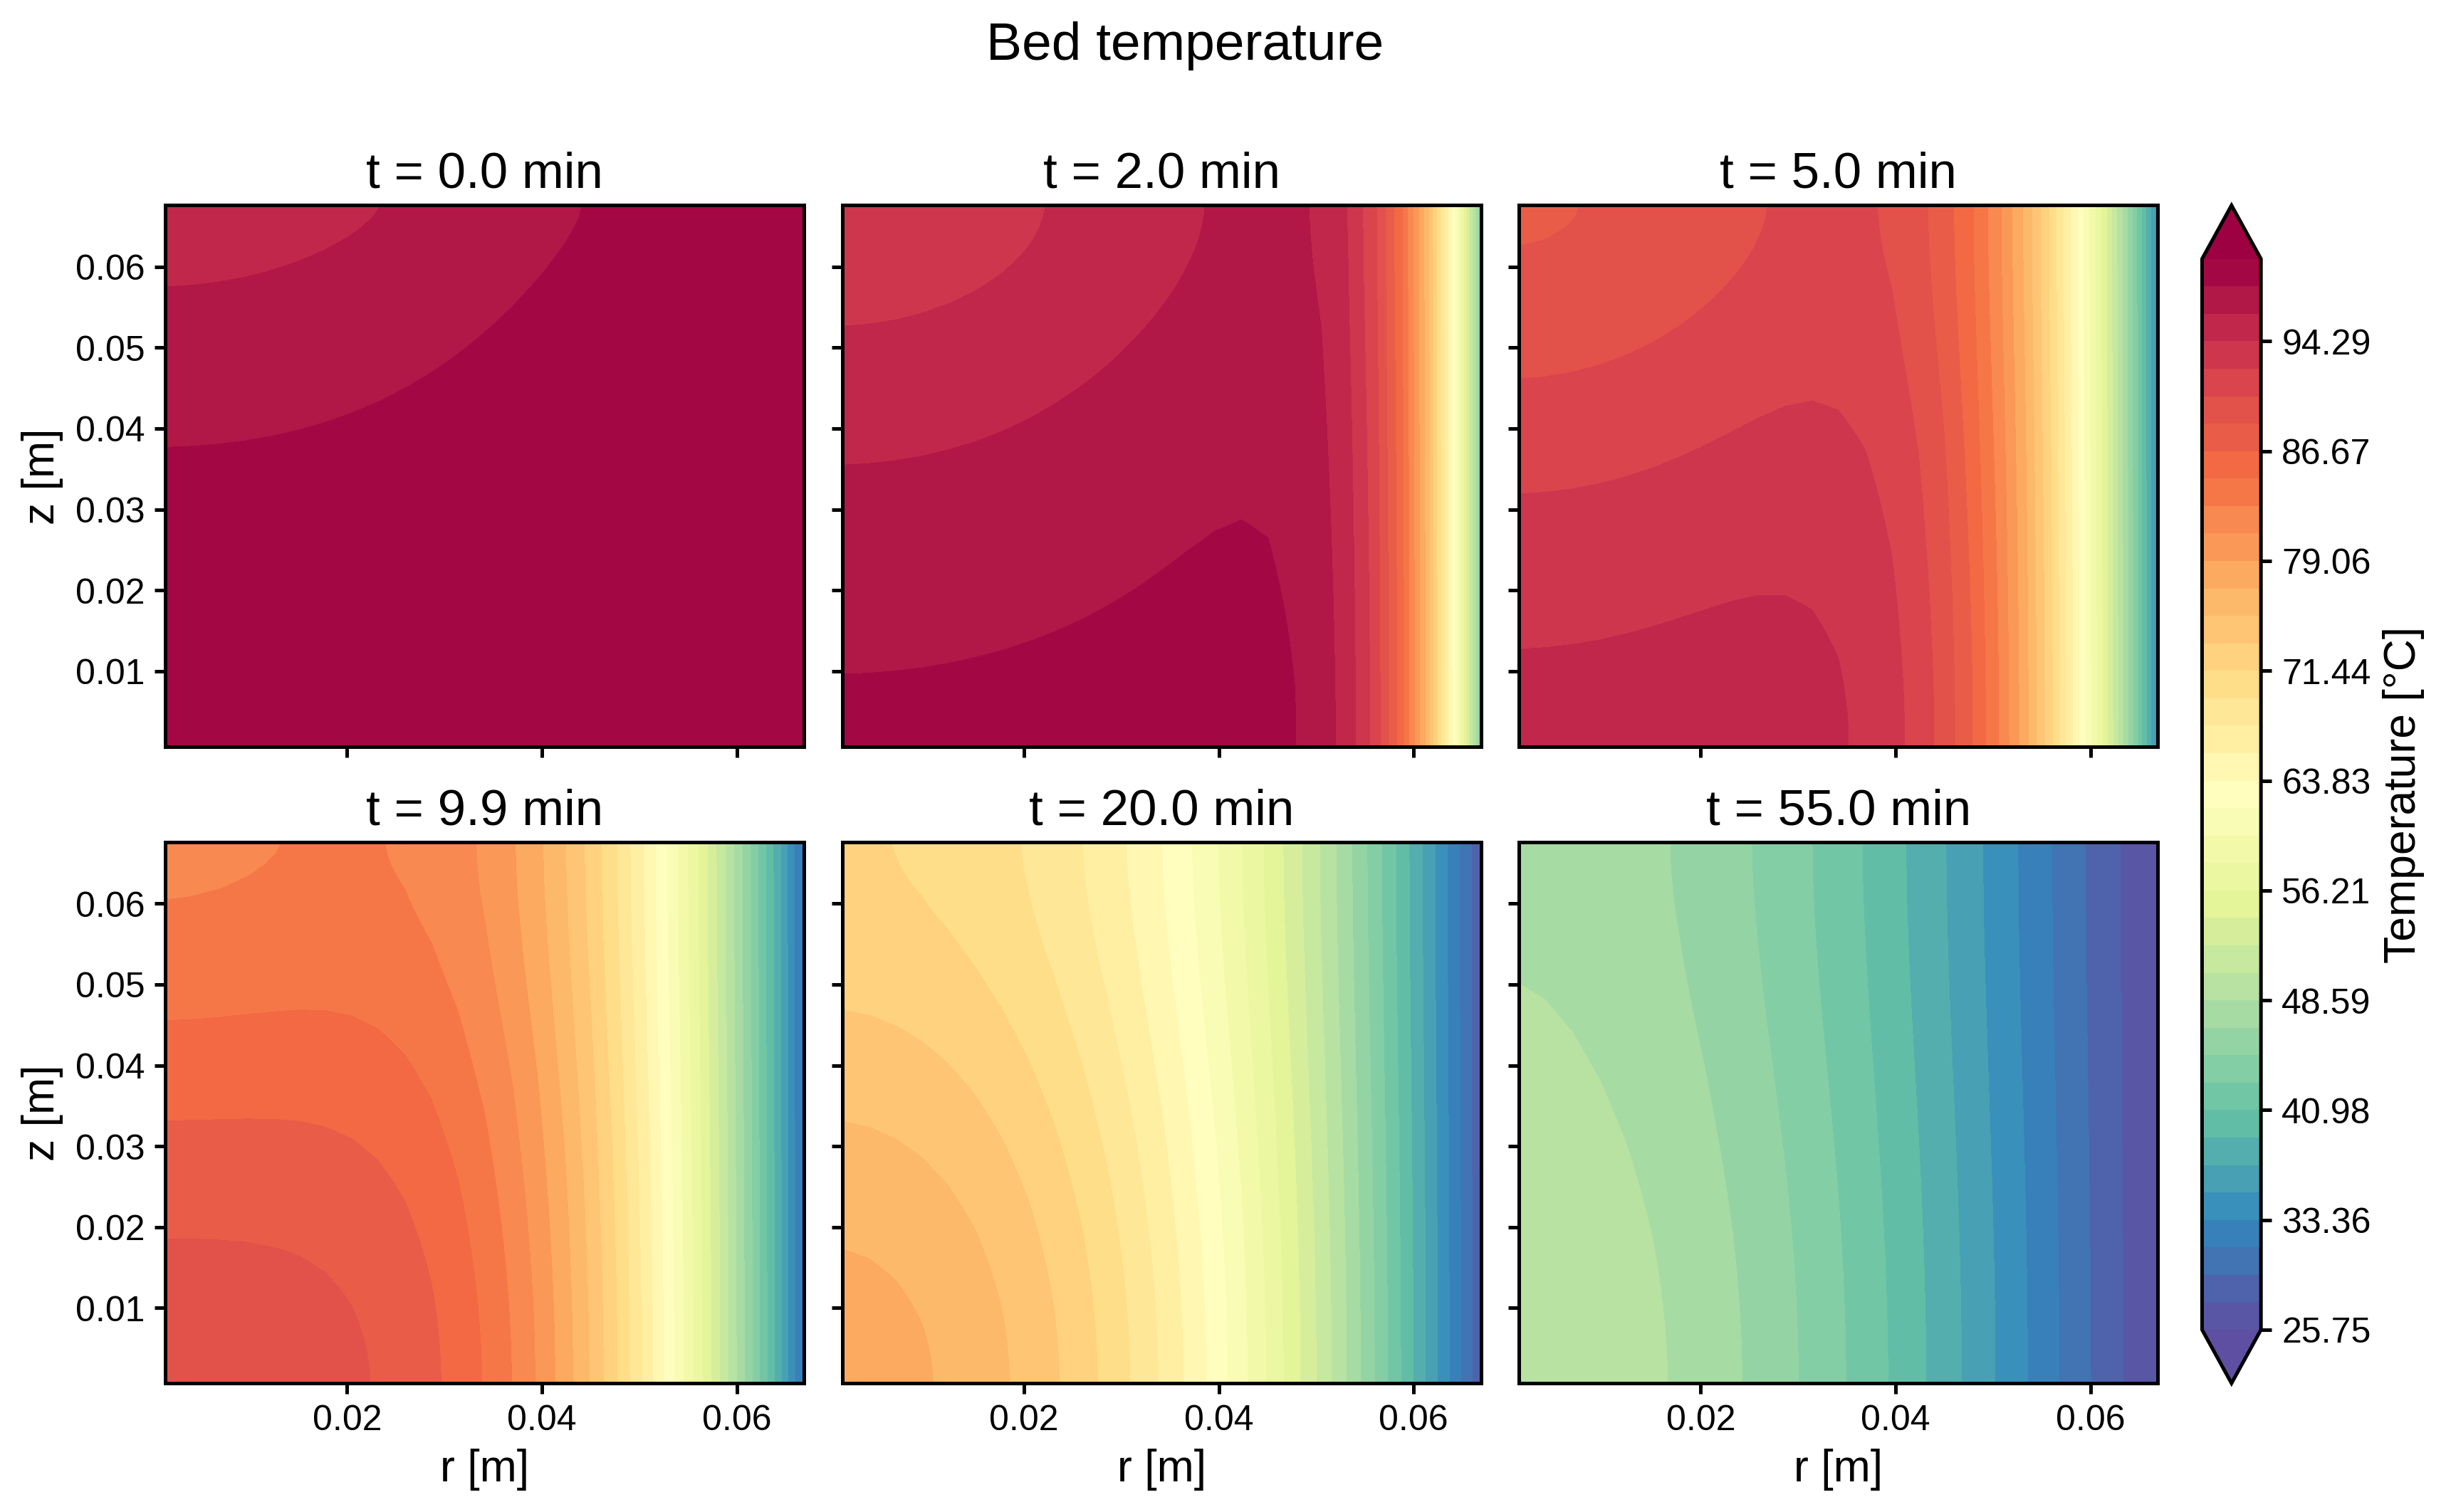

In [17]:
# Draw the step plots of the CSS cycle again, with other times for the bed temperature in `cool`
cool_times = {"cool": {"T_bed": {"times": [0, 2, 5, 10, 20, 55], "unit": "min"}}}
# Pass the heat times of the run too: otherwise the heat maps go back to the default times
pydac.report(result.folder, snapshot_times={**snapshot_times, **cool_times})

# The new map of the bed temperature during `cool`
display(Image(filename=result.results_folder / loader.cycle_label / "cool" / "profiles" / "internal_2D_profiles" / "cool_Tbed_2D_snapshots.png", width=700))

What the new map shows:
- after 2 minutes only a thin layer next to the wall is cold;
- the cold front moves towards the axis during the first 20 minutes;
- at the end of `cool` the wall side is close to 30 °C, while the axis is still around 45-50 °C.

## Continue a run

A run that stops at `execution.max_cycles` without reaching CSS can continue from its last cycle.

Just to show how this works, we try a quick resume request with `execution.max_cycles` raised to 80. This run has already reached CSS, so pyDAC refuses the request:

- `pydac.resume(folder, settings={"execution.max_cycles": 80})`;
- it continues in the same folder.

In [18]:
# Try to continue a run that already reached CSS: we expect a refusal
try:
    pydac.resume(result.folder, settings={"execution.max_cycles": 80})
except pydac.RunRefused as error:
    print("Refused:", error)

Refused: The CSS run in `/path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_03_packed_bed_a99e48db` already reached cyclic steady state at cycle 3.


## Disk use

Every cycle keeps its folder, with the full solution of each step. \
Some runs (especially 2D) can use a significant amount of disk space, so it is important to monitor disk usage.

In [19]:
def size_mb(folder):
    # Total size of the files in a folder, in MB
    return sum(path.stat().st_size for path in folder.rglob("*") if path.is_file()) / 1e6


# Size of each cycle folder, then of the whole run folder
for folder in sorted(result.results_folder.glob("cycle_*")):
    print(f"{folder.name}: {size_mb(folder):7.0f} MB")
print(f"run folder: {size_mb(result.folder):7.0f} MB")

cycle_1:     250 MB
cycle_2:     250 MB
cycle_3:     283 MB
run folder:     789 MB


Need less disk? Be sure to set the option `execution.keep_only_final_cycle = true`.
- When the run ends, it deletes every cycle folder except the reported one.
- The CSS checks of the earlier cycles (read above) go with them.

## The same from the terminal

Run these from the folder of this notebook:

```bash
# The CSS run, with the same times of the heat maps
pydac css --config ../cases/03_css_tvsa.json --snapshot-times '{"heat": {"T_bed": {"times": [1, 5, 10, 20, 30, 150], "unit": "min"}, "q_CO2": {"times": [5, 15, 30, 60, 90, 150], "unit": "min"}}}' --overwrite

# The report again, as PDF
pydac css --report simulation_results/cyclic_mode/RUN --set execution.plot_format=pdf

# The step plots again, with other times for the cool map (and the same heat times as the run)
pydac css --report simulation_results/cyclic_mode/RUN --snapshot-times '{"heat": {"T_bed": {"times": [1, 5, 10, 20, 30, 150], "unit": "min"}, "q_CO2": {"times": [5, 15, 30, 60, 90, 150], "unit": "min"}}, "cool": {"T_bed": {"times": [0, 2, 5, 10, 20, 55], "unit": "min"}}}'
```

- `RUN` is the run folder name the first command prints (`tutorial_03_packed_bed_…`).
- The same KPIs of the terminal output are in `kpis/`.

**Previous:** [Tutorial 02: Build your own case](02_custom_case.ipynb).\
**Next:** [Tutorial 04: 1D or 2D](04_1d_vs_2d.ipynb).